In [ ]:

import pandas as pd

# NYC 311 dataset API
url = "https://data.cityofnewyork.us/resource/erm2-nwe9.csv?$limit=50000&$order=created_date%20DESC"

# Download dataset
df = pd.read_csv(url)

# Save dataset
df.to_csv("/content/nyc_311_sample.csv", index=False)

# Check dataset
print("Dataset downloaded successfully!")
print("Shape:", df.shape)
print(df.head())


/tmp/ipykernel_1749/3144261179.py:7: DtypeWarning: Columns (35) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url)


Dataset downloaded successfully!
Shape: (50000, 44)
   unique_key             created_date closed_date agency  \
0    71067867  2026-11-11T02:56:07.000         NaN    DOT   
1    71070234  2026-11-11T02:06:07.000         NaN   NYPD   
2    71078889  2026-11-11T02:06:01.000         NaN    DEP   
3    71078389  2026-11-11T02:04:59.000         NaN   NYPD   
4    71079981  2026-11-11T02:04:46.000         NaN  DOHMH   

                               agency_name      complaint_type  \
0             Department of Transportation    Street Condition   
1          New York City Police Department  Noise - Commercial   
2   Department of Environmental Protection               Noise   
3          New York City Police Department     Noise - Vehicle   
4  Department of Health and Mental Hygiene              Rodent   

                     descriptor                                descriptor_2  \
0                       Pothole                                         NaN   
1              Loud Music/

In [ ]:
from google.colab import files

files.download("/content/nyc_311_sample.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Dataset overview

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nComplaint Categories:")
print(df['complaint_type'].value_counts().head(15))


Dataset Shape: (50000, 44)

Column Names:
['unique_key', 'created_date', 'closed_date', 'agency', 'agency_name', 'complaint_type', 'descriptor', 'descriptor_2', 'location_type', 'incident_zip', 'incident_address', 'street_name', 'cross_street_1', 'cross_street_2', 'intersection_street_1', 'intersection_street_2', 'address_type', 'city', 'landmark', 'facility_type', 'status', 'due_date', 'resolution_description', 'resolution_action_updated_date', 'community_board', 'council_district', 'police_precinct', 'bbl', 'borough', 'x_coordinate_state_plane', 'y_coordinate_state_plane', 'open_data_channel_type', 'park_facility_name', 'park_borough', 'vehicle_type', 'taxi_company_borough', 'taxi_pick_up_location', 'bridge_highway_name', 'bridge_highway_direction', 'road_ramp', 'bridge_highway_segment', 'latitude', 'longitude', 'location']

Data Types:
unique_key                          int64
created_date                       object
closed_date                        object
agency                 

In [ ]:
# Step 2: Create our working dataset

selected_columns = [
    'complaint_type',
    'descriptor',
    'descriptor_2',
    'location_type',
    'borough',
    'created_date',
    'closed_date',
    'agency',
    'latitude',
    'longitude',
    'status'
]

df_ml = df[selected_columns].copy()

print("Working Dataset Shape:", df_ml.shape)

print("\nTop 20 Complaint Categories:")
print(df_ml['complaint_type'].value_counts().head(20))

print("\nMissing Values in Selected Columns:")
print(df_ml.isnull().sum())

Working Dataset Shape: (50000, 11)

Top 20 Complaint Categories:
complaint_type
Illegal Parking            8963
HEAT/HOT WATER             5546
Noise - Residential        5030
Blocked Driveway           2639
UNSANITARY CONDITION       1961
Noise - Street/Sidewalk    1937
PLUMBING                   1051
Noise                      1015
PAINT/PLASTER               888
Street Light Condition      882
Abandoned Vehicle           874
Noise - Commercial          874
Street Condition            820
DOOR/WINDOW                 768
Encampment                  719
Dirty Condition             701
GENERAL                     675
WATER LEAK                  664
Water Maintenance           634
Noise - Vehicle             628
Name: count, dtype: int64

Missing Values in Selected Columns:
complaint_type        0
descriptor         1322
descriptor_2      31390
location_type      3499
borough               0
created_date          0
closed_date       16993
agency                0
latitude            737
l

In [ ]:
# Step 3: Handle missing values

text_columns = ['descriptor', 'descriptor_2', 'location_type']

for col in text_columns:
    df_ml[col] = df_ml[col].fillna('')

# Combine complaint details into one text feature
df_ml['text_features'] = (
    df_ml['descriptor'] + ' ' +
    df_ml['descriptor_2'] + ' ' +
    df_ml['location_type']
).str.strip()

# Check the cleaned dataset
print("Total Records:", len(df_ml))
print("Missing Text Values:", df_ml['text_features'].isnull().sum())

print("\nSample Text Features:")
print(df_ml[['text_features', 'complaint_type']].head(10))

print("\nTotal Complaint Categories:", df_ml['complaint_type'].nunique())

print("\nCategories with fewer than 20 records:")
print(df_ml['complaint_type'].value_counts()[lambda x: x < 20])

Total Records: 50000
Missing Text Values: 0

Sample Text Features:
                                       text_features           complaint_type
0                                            Pothole         Street Condition
1              Loud Music/Party  Club/Bar/Restaurant       Noise - Commercial
2  Construction Before/After Hours Building/Const...                    Noise
3                     Engine Idling  Street/Sidewalk          Noise - Vehicle
4  Condition Attracting Rodents Loose or Improper...                   Rodent
5                  Loud Music/Party  Street/Sidewalk  Noise - Street/Sidewalk
6  Chemical Vapors/Gases/Odors  3+ Family Apartme...       Indoor Air Quality
7                   Car/Truck Music  Street/Sidewalk          Noise - Vehicle
8                 Loud Music/Party  Store/Commercial       Noise - Commercial
9       Loud Music/Party  Residential Building/House      Noise - Residential

Total Complaint Categories: 148

Categories with fewer than 20 records:
co

In [ ]:
# Step 4: Keep categories with at least 50 records

category_counts = df_ml['complaint_type'].value_counts()

valid_categories = category_counts[
    category_counts >= 50
].index

df_model = df_ml[
    df_ml['complaint_type'].isin(valid_categories)
].copy()

print("Original Records:", len(df_ml))
print("Records After Filtering:", len(df_model))
print("Categories Retained:", df_model['complaint_type'].nunique())
print("Records Removed:", len(df_ml) - len(df_model))

print("\nCategory Distribution:")
print(df_model['complaint_type'].value_counts())

Original Records: 50000
Records After Filtering: 49016
Categories Retained: 75
Records Removed: 984

Category Distribution:
complaint_type
Illegal Parking                            8963
HEAT/HOT WATER                             5546
Noise - Residential                        5030
Blocked Driveway                           2639
UNSANITARY CONDITION                       1961
                                           ... 
Food Poisoning                               64
Boilers                                      63
Cannabis Retailer                            59
Litter Basket Request                        57
Special Projects Inspection Team (SPIT)      54
Name: count, Length: 75, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Input and target
X = df_model['text_features']
y = df_model['complaint_type']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Convert text into numerical features
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words='english'
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training Samples:", X_train_tfidf.shape[0])
print("Testing Samples:", X_test_tfidf.shape[0])
print("TF-IDF Features:", X_train_tfidf.shape[1])
print("Number of Classes:", y.nunique())

Training Samples: 39212
Testing Samples: 9804
TF-IDF Features: 2988
Number of Classes: 75


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Initialize model
model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Train model
model.fit(X_train_tfidf, y_train)

# Make predictions
y_pred = model.predict(X_test_tfidf)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("MODEL: LOGISTIC REGRESSION")
print("--------------------------------")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

MODEL: LOGISTIC REGRESSION
--------------------------------
Accuracy: 98.30%

Classification Report:
                                         precision    recall  f1-score   support

                              APPLIANCE       1.00      1.00      1.00        74
                      Abandoned Vehicle       1.00      1.00      1.00       175
                            Air Quality       1.00      1.00      1.00        19
                       Animal in a Park       1.00      1.00      1.00        17
                           Animal-Abuse       0.87      0.97      0.92        35
                       Blocked Driveway       1.00      1.00      1.00       528
                                Boilers       1.00      1.00      1.00        12
                           Building/Use       1.00      1.00      1.00        45
                      Cannabis Retailer       0.92      1.00      0.96        12
                     Consumer Complaint       1.00      1.00      1.00        57
       

In [ ]:
# Step 8: Error analysis

results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred,
    'Input_Text': X_test
})

incorrect = results[
    results['Actual'] != results['Predicted']
]

print("Total Test Samples:", len(results))
print("Incorrect Predictions:", len(incorrect))

print("\nSample Incorrect Predictions:")
print(incorrect.head(20).to_string(index=False))

Total Test Samples: 9804
Incorrect Predictions: 167

Sample Incorrect Predictions:
                    Actual                     Predicted                                                            Input_Text
                Encampment             Illegal Fireworks                                                       Street/Sidewalk
                Encampment General Construction/Plumbing                                                                 Other
                Encampment                   Panhandling                                            Residential Building/House
                Encampment             Illegal Fireworks                                                       Street/Sidewalk
                Encampment             Illegal Fireworks                                                       Street/Sidewalk
For Hire Vehicle Complaint                Taxi Complaint Driver Complaint - Non Passenger Unauthorized Pick-Up Location Street
                Encampment  

In [ ]:
# Step 9: Investigate difficult categories

difficult_categories = [
    'Encampment',
    'Panhandling',
    'Illegal Fireworks'
]

for category in difficult_categories:

    subset = df_model[
        df_model['complaint_type'] == category
    ]

    print(f"\n{'='*50}")
    print("CATEGORY:", category)
    print("Total Records:", len(subset))

    print("\nMissing Descriptor:")
    print((subset['descriptor'] == '').sum())

    print("Missing Descriptor 2:")
    print((subset['descriptor_2'] == '').sum())

    print("\nSample Records:")
    print(subset[
        ['descriptor', 'descriptor_2', 'location_type']
    ].head(10).to_string(index=False))


CATEGORY: Encampment
Total Records: 719

Missing Descriptor:
719
Missing Descriptor 2:
719

Sample Records:
descriptor descriptor_2              location_type
                        Residential Building/House
                                            Subway
                        Residential Building/House
                                  Store/Commercial
                        Residential Building/House
                                   Street/Sidewalk
                                   Street/Sidewalk
                                   Street/Sidewalk
                                   Street/Sidewalk
                                   Street/Sidewalk

CATEGORY: Panhandling
Total Records: 187

Missing Descriptor:
187
Missing Descriptor 2:
187

Sample Records:
descriptor descriptor_2              location_type
                                            Subway
                        Residential Building/House
                                   Street/Sidewalk
                

In [ ]:
# Step 10: Test real-world complaint inputs

test_complaints = [
    "There is a large pothole on the main road causing accidents.",
    "Garbage has not been collected for three days.",
    "Loud music from a nearby restaurant is disturbing residents.",
    "Water is leaking continuously from a damaged pipeline.",
    "Street lights are not working at night.",
    "Someone is illegally parking vehicles and blocking the road.",
    "There is a homeless encampment near the public park.",
    "People are setting off fireworks on the street."
]

for complaint in test_complaints:

    transformed = tfidf.transform([complaint])
    prediction = model.predict(transformed)[0]

    probabilities = model.predict_proba(transformed)[0]
    confidence = probabilities.max() * 100

    print("\nComplaint:", complaint)
    print("Predicted Category:", prediction)
    print(f"Model Confidence: {confidence:.2f}%")
    print("-" * 60)


Complaint: There is a large pothole on the main road causing accidents.
Predicted Category: Street Condition
Model Confidence: 61.39%
------------------------------------------------------------

Complaint: Garbage has not been collected for three days.
Predicted Category: Maintenance or Facility
Model Confidence: 12.65%
------------------------------------------------------------

Complaint: Loud music from a nearby restaurant is disturbing residents.
Predicted Category: Noise - Commercial
Model Confidence: 52.77%
------------------------------------------------------------

Complaint: Water is leaking continuously from a damaged pipeline.
Predicted Category: PLUMBING
Model Confidence: 22.88%
------------------------------------------------------------

Complaint: Street lights are not working at night.
Predicted Category: General Construction/Plumbing
Model Confidence: 8.22%
------------------------------------------------------------

Complaint: Someone is illegally parking vehicle

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Word-level features
word_tfidf = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

# Character-level features
char_tfidf = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(2, 5),
    max_features=10000,
    sublinear_tf=True
)

# Combine both feature types
combined_tfidf = FeatureUnion([
    ('word', word_tfidf),
    ('char', char_tfidf)
])

# Transform training and testing data
X_train_combined = combined_tfidf.fit_transform(X_train)
X_test_combined = combined_tfidf.transform(X_test)

# Train improved classifier
improved_model = LogisticRegression(
    max_iter=1500,
    class_weight='balanced',
    C=2,
    random_state=42
)

improved_model.fit(X_train_combined, y_train)

# Evaluate
improved_pred = improved_model.predict(X_test_combined)

print("Improved Model Accuracy:",
      accuracy_score(y_test, improved_pred) * 100)

print("\nClassification Report:")
print(classification_report(
    y_test,
    improved_pred,
    zero_division=0
))

Improved Model Accuracy: 98.29661362709098

Classification Report:
                                         precision    recall  f1-score   support

                              APPLIANCE       1.00      1.00      1.00        74
                      Abandoned Vehicle       1.00      1.00      1.00       175
                            Air Quality       1.00      1.00      1.00        19
                       Animal in a Park       1.00      1.00      1.00        17
                           Animal-Abuse       0.87      0.97      0.92        35
                       Blocked Driveway       1.00      1.00      1.00       528
                                Boilers       1.00      1.00      1.00        12
                           Building/Use       1.00      1.00      1.00        45
                      Cannabis Retailer       0.92      1.00      0.96        12
                     Consumer Complaint       1.00      1.00      1.00        57
                         Curb Condition  

In [ ]:
from sklearn.model_selection import train_test_split

# Citizen-style complaint examples
citizen_data = {
    'Street Condition': [
        "There is a deep pothole on the road.",
        "The road surface is broken and damaged.",
        "Large cracks have appeared on the street.",
        "A pothole is causing traffic to slow down.",
        "The pavement is badly damaged near the junction."
    ],

    'Missed Collection': [
        "Garbage has not been collected for several days.",
        "The waste collection truck skipped our street.",
        "Trash is piling up because pickup was missed.",
        "Our garbage bins are overflowing after missed collection.",
        "Municipal workers have not collected rubbish this week."
    ],

    'Noise - Commercial': [
        "A restaurant is playing loud music late at night.",
        "Music from a nearby bar is disturbing residents.",
        "A commercial venue is creating excessive noise.",
        "A club is playing music loudly after permitted hours.",
        "Loud speakers outside a shop are disturbing people."
    ],

    'WATER LEAK': [
        "Water is flowing from a broken water main.",
        "A pipe has burst and water is flooding the road.",
        "There is continuous leakage from a pipeline.",
        "Water is gushing from a damaged street pipe.",
        "The public water supply pipe is leaking."
    ],

    'Street Light Condition': [
        "Street lamps are not turning on after dark.",
        "The streetlight near my house is broken.",
        "Several street lights have stopped working.",
        "The road is completely dark because lights are not working.",
        "The light pole near the bus stop is not illuminating."
    ],

    'Illegal Parking': [
        "A car is illegally parked and blocking the driveway.",
        "Vehicles are parked in a no parking zone.",
        "Someone has parked a car blocking our entrance.",
        "Cars are obstructing the street.",
        "An illegally parked vehicle is blocking traffic."
    ],

    'Encampment': [
        "There is a homeless encampment near the public park.",
        "Several tents have been set up on the sidewalk.",
        "A group has established a camp under the bridge.",
        "People are camping in a public space.",
        "A makeshift camp has appeared near the park entrance."
    ],

    'Illegal Fireworks': [
        "People are setting off fireworks in the street.",
        "Firecrackers are being launched illegally nearby.",
        "Someone is lighting fireworks late at night.",
        "Repeated fireworks are being set off in a public area.",
        "People are using fireworks where they are prohibited."
    ]
}

# Convert examples into a DataFrame
citizen_df = pd.DataFrame([
    {'text_features': complaint, 'complaint_type': category}
    for category, complaints in citizen_data.items()
    for complaint in complaints
])

# Split into training and testing examples
citizen_train, citizen_test = train_test_split(
    citizen_df,
    test_size=0.20,
    random_state=42,
    stratify=citizen_df['complaint_type']
)

print("Total Citizen Examples:", len(citizen_df))
print("Citizen Training Examples:", len(citizen_train))
print("Citizen Testing Examples:", len(citizen_test))
print("\nCategory Distribution:")
print(citizen_df['complaint_type'].value_counts())

Total Citizen Examples: 40
Citizen Training Examples: 32
Citizen Testing Examples: 8

Category Distribution:
complaint_type
Street Condition          5
Missed Collection         5
Noise - Commercial        5
WATER LEAK                5
Street Light Condition    5
Illegal Parking           5
Encampment                5
Illegal Fireworks         5
Name: count, dtype: int64


In [ ]:
# Step 13: Combine training datasets

X_combined_train = pd.concat([
    X_train.reset_index(drop=True),
    citizen_train['text_features'].reset_index(drop=True)
])

y_combined_train = pd.concat([
    y_train.reset_index(drop=True),
    citizen_train['complaint_type'].reset_index(drop=True)
])

# Train a fresh TF-IDF vectorizer
final_tfidf = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_final_train = final_tfidf.fit_transform(X_combined_train)

# Train classifier
final_model = LogisticRegression(
    max_iter=1500,
    class_weight='balanced',
    random_state=42
)

final_model.fit(X_final_train, y_combined_train)

print("Combined Training Records:", len(X_combined_train))
print("Final TF-IDF Features:", X_final_train.shape[1])
print("Final Model Training Completed!")

Combined Training Records: 39244
Final TF-IDF Features: 3587
Final Model Training Completed!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Transform unseen citizen test examples
X_citizen_test = final_tfidf.transform(
    citizen_test['text_features']
)

# Predict categories
citizen_predictions = final_model.predict(X_citizen_test)

# Display individual predictions
citizen_results = pd.DataFrame({
    'Complaint': citizen_test['text_features'].values,
    'Actual': citizen_test['complaint_type'].values,
    'Predicted': citizen_predictions
})

citizen_results['Correct'] = (
    citizen_results['Actual'] == citizen_results['Predicted']
)

print("CITIZEN LANGUAGE TEST RESULTS")
print("=" * 60)
print(citizen_results.to_string(index=False))

print("\nAccuracy:",
      f"{accuracy_score(citizen_test['complaint_type'], citizen_predictions) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    citizen_test['complaint_type'],
    citizen_predictions,
    zero_division=0
))

CITIZEN LANGUAGE TEST RESULTS
                                                  Complaint                 Actual                               Predicted  Correct
                    The road surface is broken and damaged.       Street Condition                Traffic Signal Condition    False
               Water is gushing from a damaged street pipe.             WATER LEAK                     Illegal Tree Damage    False
                      People are camping in a public space.             Encampment Special Projects Inspection Team (SPIT)    False
      People are using fireworks where they are prohibited.      Illegal Fireworks           General Construction/Plumbing    False
            Someone has parked a car blocking our entrance.        Illegal Parking                      Consumer Complaint    False
        Loud speakers outside a shop are disturbing people.     Noise - Commercial                      Consumer Complaint    False
    Municipal workers have not collected rubbi

In [ ]:
# Step 15: Create citizen-language dataset

citizen_data = {
    'Street Condition': [
        "There is a deep pothole on the main road.",
        "The road is badly damaged near the bus stop.",
        "Large cracks have appeared on the road.",
        "A broken road is causing accidents.",
        "The street surface needs urgent repair."
    ],
    'Missed Collection': [
        "Garbage has not been collected for three days.",
        "Trash is overflowing from the bins.",
        "The garbage truck skipped our street.",
        "Waste is piling up outside our homes.",
        "Municipal workers missed the garbage pickup."
    ],
    'Noise - Commercial': [
        "A restaurant is playing loud music at night.",
        "A nearby bar is disturbing residents with music.",
        "Loud speakers outside a shop are creating noise.",
        "A commercial venue is playing music after midnight.",
        "The nightclub noise is disturbing our neighbourhood."
    ],
    'WATER LEAK': [
        "Water is leaking from a damaged pipeline.",
        "A broken water pipe is flooding the street.",
        "There is continuous water leakage near my house.",
        "Water is flowing from a damaged public pipe.",
        "A pipeline has burst near the road."
    ],
    'Street Light Condition': [
        "Street lights are not working at night.",
        "The lamp post near my house is broken.",
        "Our street becomes completely dark after sunset.",
        "Several street lights have stopped working.",
        "The road has no working street lamps."
    ],
    'Illegal Parking': [
        "A car is blocking our building entrance.",
        "Vehicles are parked in a no parking zone.",
        "Someone has illegally parked on the footpath.",
        "A vehicle is blocking the main road.",
        "Cars are obstructing the driveway."
    ],
    'Encampment': [
        "There is a homeless encampment near the park.",
        "Several tents have appeared on the sidewalk.",
        "People are camping under the bridge.",
        "A temporary camp has been set up in a public area.",
        "There is an encampment near the public building."
    ],
    'Illegal Fireworks': [
        "People are setting off fireworks in the street.",
        "Firecrackers are being used late at night.",
        "Someone is launching fireworks in a prohibited area.",
        "Repeated fireworks are disturbing the neighbourhood.",
        "People are lighting firecrackers near residential homes."
    ]
}

print("Initial citizen dataset created!")

Initial citizen dataset created!


In [ ]:
citizen_df = pd.DataFrame([
    {
        'complaint_text': complaint,
        'complaint_type': category
    }
    for category, complaints in citizen_data.items()
    for complaint in complaints
])

print("Dataset shape:", citizen_df.shape)
print("\nCategory distribution:")
print(citizen_df['complaint_type'].value_counts())

Dataset shape: (40, 2)

Category distribution:
complaint_type
Street Condition          5
Missed Collection         5
Noise - Commercial        5
WATER LEAK                5
Street Light Condition    5
Illegal Parking           5
Encampment                5
Illegal Fireworks         5
Name: count, dtype: int64


In [ ]:
# Step 3: Prepare dataset expansion

additional_complaints = {
    'Street Condition': [],
    'Missed Collection': [],
    'Noise - Commercial': [],
    'WATER LEAK': [],
    'Street Light Condition': [],
    'Illegal Parking': [],
    'Encampment': [],
    'Illegal Fireworks': []
}

print("Categories ready for expansion:")
for category, complaints in additional_complaints.items():
    print(category, ":", len(complaints), "new examples needed:", 25)

Categories ready for expansion:
Street Condition : 0 new examples needed: 25
Missed Collection : 0 new examples needed: 25
Noise - Commercial : 0 new examples needed: 25
WATER LEAK : 0 new examples needed: 25
Street Light Condition : 0 new examples needed: 25
Illegal Parking : 0 new examples needed: 25
Encampment : 0 new examples needed: 25
Illegal Fireworks : 0 new examples needed: 25


In [ ]:
additional_complaints['Street Condition'] = [
    "A huge pothole has formed near the school entrance.",
    "The road is full of cracks and uneven surfaces.",
    "A damaged road is making it difficult for vehicles to pass.",
    "There is a pothole in the middle of the residential street.",
    "The road surface has broken after heavy rainfall.",
    "Several potholes have appeared along the main road.",
    "The pavement is damaged near the market.",
    "A section of the road has collapsed.",
    "The road is covered with loose gravel and broken asphalt.",
    "There is a dangerous hole near the traffic junction.",
    "Vehicles are struggling to pass through the damaged road.",
    "The road near our apartment has not been repaired.",
    "A large crack is spreading across the street.",
    "The road surface is uneven and causing accidents.",
    "The street has become difficult to use because of potholes.",
    "A damaged patch of road is blocking smooth traffic movement.",
    "The road near the hospital needs immediate repair.",
    "There are multiple holes along the residential road.",
    "The asphalt has come off near the bus stop.",
    "A broken section of pavement is creating a hazard.",
    "The road is badly worn out near the intersection.",
    "Rainwater has damaged the road surface.",
    "A deep hole has appeared near the railway crossing.",
    "The street surface is crumbling and needs maintenance.",
    "The damaged road is causing problems for two-wheelers."
]

print("Street Condition:", len(additional_complaints['Street Condition']))

Street Condition: 25


In [ ]:
additional_complaints['Missed Collection'] = [
    "The garbage collection vehicle has not visited our street.",
    "Waste has been left uncollected outside our apartment.",
    "Our garbage bins have been full for several days.",
    "The sanitation team skipped our neighbourhood today.",
    "Household waste is accumulating near the roadside.",
    "Garbage has been overflowing from the public dustbin.",
    "The waste collection service is not operating regularly.",
    "Nobody has collected the trash from our street this week.",
    "The garbage truck missed its scheduled pickup.",
    "Uncollected rubbish is creating a bad smell.",
    "The bins near the market are overflowing with waste.",
    "Our street has not received garbage collection for days.",
    "Waste is scattered around the collection point.",
    "The municipal waste vehicle did not arrive this morning.",
    "Garbage bags are piling up outside residential buildings.",
    "The public dustbins have not been emptied.",
    "The sanitation department missed our scheduled collection.",
    "Household rubbish is remaining on the roadside.",
    "The garbage pickup service has been delayed repeatedly.",
    "Waste is accumulating near the community park.",
    "The collection point has not been cleaned for days.",
    "Our neighbourhood has been skipped during waste collection.",
    "The garbage bins are overflowing near the bus stop.",
    "Municipal workers have not removed the accumulated rubbish.",
    "The street is becoming unhygienic due to missed pickups."
]

print("Missed Collection:", len(additional_complaints['Missed Collection']))

Missed Collection: 25


In [ ]:
additional_complaints['Noise - Commercial'] = [
    "A nearby restaurant is playing loud music late at night.",
    "The music from a commercial shop is disturbing residents.",
    "A bar is creating excessive noise after closing hours.",
    "Loud speakers outside a store are disturbing the neighbourhood.",
    "A party hall is playing music at an unreasonable volume.",
    "The noise from a nearby hotel continues past midnight.",
    "A commercial event is disturbing people with loud speakers.",
    "The music from a pub can be heard throughout our street.",
    "A restaurant is using loud speakers during late hours.",
    "Continuous noise from a shopping complex is disturbing us.",
    "A nearby business is playing extremely loud music.",
    "The sound system outside a shop is too loud.",
    "A commercial establishment is disturbing nearby residents.",
    "Loud music from a banquet hall continues every night.",
    "The noise from a cafe is affecting nearby homes.",
    "A shop is using a microphone at a very high volume.",
    "A nightclub is creating excessive noise during the night.",
    "The loud music from a commercial event is disturbing our sleep.",
    "A business is operating noisy equipment late at night.",
    "The speakers outside a showroom are disturbing pedestrians.",
    "A nearby restaurant is creating repeated noise complaints.",
    "Commercial loudspeakers are causing disturbance in our area.",
    "The music from a wedding venue is extremely loud.",
    "A gym is playing loud music that disturbs neighbouring houses.",
    "Noise from a commercial building continues late into the night."
]

print("Noise - Commercial:", len(additional_complaints['Noise - Commercial']))

Noise - Commercial: 25


In [ ]:
additional_complaints['WATER LEAK'] = [
    "Clean water is leaking continuously from a street pipe.",
    "A water pipeline has burst near our apartment.",
    "There is a major leak in the public water supply line.",
    "Water is flowing onto the road from a broken pipe.",
    "A damaged underground pipeline is causing water leakage.",
    "The water pipe near the school is leaking.",
    "A continuous stream of water is coming from a broken valve.",
    "The roadside water pipeline needs urgent repair.",
    "Water is flooding the street because of a pipe leak.",
    "A public water connection is leaking near the bus stop.",
    "There is water wastage due to a damaged pipeline.",
    "The main water supply pipe has developed a crack.",
    "Water is leaking from the connection outside our building.",
    "A broken pipe is causing water to collect on the road.",
    "The pipeline near the market is leaking heavily.",
    "Water is escaping from a damaged municipal pipe.",
    "A water leak has created a puddle near the junction.",
    "The street is flooded due to a leaking water line.",
    "A faulty water valve is allowing water to flow continuously.",
    "The public water pipe needs immediate maintenance.",
    "Water is spilling from a damaged supply connection.",
    "A pipeline leak is wasting drinking water.",
    "There is a leak in the water main near our street.",
    "The pipe outside our house is releasing water constantly.",
    "A damaged water line is causing flooding near the footpath."
]

print("WATER LEAK:", len(additional_complaints['WATER LEAK']))

WATER LEAK: 25


In [ ]:
additional_complaints['Street Light Condition'] = [
    "The street light outside our house is not working.",
    "The entire road becomes dark after sunset.",
    "A street lamp near the school has stopped working.",
    "Several lights along our street are not functioning.",
    "The lamp post near the bus stop is damaged.",
    "There is no proper street lighting near the park.",
    "The street light keeps switching off at night.",
    "A broken street lamp is leaving the road in darkness.",
    "The lights near the residential area are not working.",
    "The street lamp has been out of service for a week.",
    "The road near the hospital has no working street lights.",
    "A damaged light pole needs repair.",
    "The street lights are flickering throughout the night.",
    "The public road is very dark due to faulty lamps.",
    "The street light near the junction is not turning on.",
    "Multiple street lamps have stopped illuminating the road.",
    "The light outside our apartment gate is broken.",
    "There is no working street lamp near the railway crossing.",
    "The street lighting system needs maintenance.",
    "A faulty street light is creating visibility problems.",
    "The lamp post near the market is not functioning.",
    "The street lights have not been repaired for several days.",
    "Our residential lane remains dark throughout the night.",
    "The street lamp is damaged and needs replacement.",
    "The road is unsafe at night because the lights are off."
]

print("Street Light Condition:", len(additional_complaints['Street Light Condition']))

Street Light Condition: 25


In [ ]:
additional_complaints['Illegal Parking'] = [
    "A car is parked in front of our building entrance.",
    "Vehicles are blocking the pedestrian footpath.",
    "Someone has parked a vehicle in a no parking zone.",
    "A truck is obstructing the main road.",
    "Cars are parked illegally near the school gate.",
    "A vehicle is blocking access to our apartment.",
    "Several bikes are parked on the footpath.",
    "A car has been left in front of the fire exit.",
    "Vehicles are blocking the entrance to the hospital.",
    "Someone has parked across our driveway.",
    "Illegal parking is causing traffic congestion.",
    "A parked car is blocking the pedestrian crossing.",
    "Vehicles are occupying the bus stop area.",
    "A van is obstructing the residential street.",
    "Cars are parked on both sides of the narrow road.",
    "A vehicle is blocking access to the public walkway.",
    "Someone has parked in a reserved parking space.",
    "A car is blocking the entrance to our shop.",
    "Vehicles are parked in front of the traffic sign.",
    "A motorcycle is blocking the building entrance.",
    "Illegal roadside parking is causing traffic problems.",
    "A delivery vehicle is blocking the main entrance.",
    "Cars are parked on the pavement near the market.",
    "A vehicle has been abandoned in a restricted parking area.",
    "Someone is repeatedly parking vehicles in front of our gate."
]

print("Illegal Parking:", len(additional_complaints['Illegal Parking']))

Illegal Parking: 25


In [ ]:
additional_complaints['Encampment'] = [
    "A group of people has set up tents near the public park.",
    "There is a temporary camp on the footpath.",
    "Several tents have appeared under the flyover.",
    "An encampment has formed near the railway station.",
    "People are staying in temporary shelters near the roadside.",
    "A group has established a camp in the public garden.",
    "There are multiple temporary shelters near the bridge.",
    "A tent settlement has appeared beside the public building.",
    "People are camping near the entrance of the park.",
    "A temporary settlement is occupying part of the sidewalk.",
    "Several makeshift shelters have been set up near the bus station.",
    "There is an encampment beside the highway.",
    "Temporary tents are occupying a public walkway.",
    "A group has set up shelters near the community centre.",
    "People are living in makeshift tents near the roadside.",
    "A temporary camp has appeared near the playground.",
    "There are several tents under the railway bridge.",
    "An encampment is occupying space near the public library.",
    "Makeshift shelters have been placed along the footpath.",
    "A temporary settlement has formed near the market area.",
    "There are tents set up beside the public parking area.",
    "A group is camping near the entrance to the bus depot.",
    "Temporary shelters have appeared near the canal walkway.",
    "A roadside encampment has expanded into the pedestrian area.",
    "Several people have established a temporary camp near the park."
]

print("Encampment:", len(additional_complaints['Encampment']))

Encampment: 25


In [ ]:
additional_complaints['Illegal Fireworks'] = [
    "People are setting off fireworks in a restricted area.",
    "Firecrackers are being burst late at night.",
    "Someone is launching fireworks near residential buildings.",
    "Repeated firecracker explosions are disturbing residents.",
    "People are using fireworks near a hospital.",
    "Loud firecrackers are being set off after midnight.",
    "Someone is lighting fireworks on the public road.",
    "Fireworks are being used near a petrol station.",
    "People are bursting crackers in a prohibited zone.",
    "A group is setting off fireworks near the school.",
    "Illegal fireworks are causing noise in our neighbourhood.",
    "Someone is launching rockets from a crowded street.",
    "Firecrackers are being used near parked vehicles.",
    "People are setting off fireworks in a public park.",
    "Repeated fireworks are disturbing the nearby residents.",
    "Someone is bursting crackers in a residential lane.",
    "Fireworks are being launched close to a crowded market.",
    "People are using explosive firecrackers late at night.",
    "A group is setting off fireworks near the bus stop.",
    "Firecrackers are being burst close to elderly residents.",
    "Someone is launching fireworks near dry vegetation.",
    "Fireworks are being used without permission at a public event.",
    "People are bursting loud crackers near apartment buildings.",
    "Illegal firecracker activity is happening on our street.",
    "A group is setting off fireworks in a restricted public space."
]

print("Illegal Fireworks:", len(additional_complaints['Illegal Fireworks']))

Illegal Fireworks: 25


In [ ]:
# Combine original and additional complaints

additional_df = pd.DataFrame([
    {
        'complaint_text': complaint,
        'complaint_type': category
    }
    for category, complaints in additional_complaints.items()
    for complaint in complaints
])

citizen_final_df = pd.concat(
    [citizen_df, additional_df],
    ignore_index=True
)

print("Final Dataset Shape:", citizen_final_df.shape)
print("\nCategory Distribution:")
print(citizen_final_df['complaint_type'].value_counts())

print("\nMissing Values:")
print(citizen_final_df.isnull().sum())

Final Dataset Shape: (240, 2)

Category Distribution:
complaint_type
Street Condition          30
Missed Collection         30
Noise - Commercial        30
WATER LEAK                30
Street Light Condition    30
Illegal Parking           30
Encampment                30
Illegal Fireworks         30
Name: count, dtype: int64

Missing Values:
complaint_text    0
complaint_type    0
dtype: int64


In [ ]:
# Check duplicate complaint texts

duplicate_count = citizen_final_df['complaint_text'].duplicated().sum()

print("Total Complaints:", len(citizen_final_df))
print("Duplicate Complaints:", duplicate_count)

if duplicate_count == 0:
    print("Dataset is ready for preprocessing!")
else:
    print("Duplicates found. Let's inspect them.")

Total Complaints: 240
Duplicate Complaints: 0
Dataset is ready for preprocessing!


In [ ]:
from sklearn.model_selection import train_test_split

X = citizen_final_df['complaint_text']
y = citizen_final_df['complaint_type']

X_train_citizen, X_test_citizen, y_train_citizen, y_test_citizen = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train_citizen))
print("Testing samples:", len(X_test_citizen))

print("\nTraining distribution:")
print(y_train_citizen.value_counts())

print("\nTesting distribution:")
print(y_test_citizen.value_counts())

Training samples: 192
Testing samples: 48

Training distribution:
complaint_type
WATER LEAK                24
Illegal Parking           24
Illegal Fireworks         24
Noise - Commercial        24
Missed Collection         24
Street Condition          24
Encampment                24
Street Light Condition    24
Name: count, dtype: int64

Testing distribution:
complaint_type
Encampment                6
WATER LEAK                6
Street Light Condition    6
Noise - Commercial        6
Illegal Fireworks         6
Illegal Parking           6
Missed Collection         6
Street Condition          6
Name: count, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

citizen_tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words='english',
    sublinear_tf=True
)

X_train_citizen_tfidf = citizen_tfidf.fit_transform(X_train_citizen)

X_test_citizen_tfidf = citizen_tfidf.transform(X_test_citizen)

print("Training feature shape:", X_train_citizen_tfidf.shape)
print("Testing feature shape:", X_test_citizen_tfidf.shape)

Training feature shape: (192, 886)
Testing feature shape: (48, 886)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Initialize model
citizen_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Train model
citizen_model.fit(
    X_train_citizen_tfidf,
    y_train_citizen
)

# Predict test data
citizen_predictions = citizen_model.predict(
    X_test_citizen_tfidf
)

# Evaluate model
accuracy = accuracy_score(
    y_test_citizen,
    citizen_predictions
)

print("Citizen Complaint Model Training Completed!")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test_citizen,
    citizen_predictions,
    zero_division=0
))

Citizen Complaint Model Training Completed!
Accuracy: 87.5 %

Classification Report:
                        precision    recall  f1-score   support

            Encampment       0.75      1.00      0.86         6
     Illegal Fireworks       0.83      0.83      0.83         6
       Illegal Parking       1.00      1.00      1.00         6
     Missed Collection       1.00      0.50      0.67         6
    Noise - Commercial       1.00      1.00      1.00         6
      Street Condition       1.00      0.83      0.91         6
Street Light Condition       0.62      0.83      0.71         6
            WATER LEAK       1.00      1.00      1.00         6

              accuracy                           0.88        48
             macro avg       0.90      0.88      0.87        48
          weighted avg       0.90      0.88      0.87        48



In [ ]:
# Compare actual and predicted categories

error_analysis = pd.DataFrame({
    'Actual': y_test_citizen.values,
    'Predicted': citizen_predictions,
    'Complaint': X_test_citizen.values
})

misclassified = error_analysis[
    error_analysis['Actual'] != error_analysis['Predicted']
]

print("Total Incorrect Predictions:", len(misclassified))
print("\nMisclassified Complaints:\n")

display(misclassified)

Total Incorrect Predictions: 6

Misclassified Complaints:



,Actual,Predicted,Complaint
10,Illegal Fireworks,Street Light Condition,Illegal firecracker activity is happening on o...
18,Missed Collection,Encampment,The public dustbins have not been emptied.
30,Missed Collection,Street Light Condition,Nobody has collected the trash from our street...
33,Street Condition,Encampment,A deep hole has appeared near the railway cros...
45,Missed Collection,Street Light Condition,The street is becoming unhygienic due to misse...
47,Street Light Condition,Illegal Fireworks,Our residential lane remains dark throughout t...


In [ ]:
new_complaints = [
    "A massive pothole is damaging vehicles near the college.",
    "The municipal truck has ignored our garbage pickup for a week.",
    "A hotel is playing loud music after midnight.",
    "A water pipe has broken and water is flooding the footpath.",
    "The street lamps are not illuminating our road.",
    "A car is blocking the entrance to our residential complex.",
    "Temporary tents have been installed near the public playground.",
    "Residents are reporting illegal firecracker explosions at night."
]

new_features = citizen_tfidf.transform(new_complaints)

new_predictions = citizen_model.predict(new_features)

new_probabilities = citizen_model.predict_proba(new_features)

fresh_results = pd.DataFrame({
    'Complaint': new_complaints,
    'Predicted Category': new_predictions,
    'Confidence (%)': (
        new_probabilities.max(axis=1) * 100
    ).round(2)
})

display(fresh_results)

,Complaint,Predicted Category,Confidence (%)
0,A massive pothole is damaging vehicles near th...,Street Condition,24.77
1,The municipal truck has ignored our garbage pi...,Missed Collection,40.16
2,A hotel is playing loud music after midnight.,Noise - Commercial,51.45
3,A water pipe has broken and water is flooding ...,WATER LEAK,55.61
4,The street lamps are not illuminating our road.,Street Light Condition,33.10
5,A car is blocking the entrance to our resident...,Illegal Parking,40.13
6,Temporary tents have been installed near the p...,Encampment,49.61
7,Residents are reporting illegal firecracker ex...,Illegal Fireworks,21.37


In [ ]:
def classify_complaint(complaint):

    features = citizen_tfidf.transform([complaint])

    probabilities = citizen_model.predict_proba(features)[0]

    top_indices = probabilities.argsort()[-3:][::-1]

    predicted_category = citizen_model.classes_[top_indices[0]]
    confidence = probabilities[top_indices[0]] * 100

    if confidence >= 40:
        status = "Prediction available"
    else:
        status = "Needs human review"

    print("Complaint:", complaint)
    print("\nPredicted Category:", predicted_category)
    print("Confidence:", round(confidence, 2), "%")
    print("Status:", status)

    print("\nTop 3 Possible Categories:")

    for index in top_indices:
        print(
            citizen_model.classes_[index],
            "-",
            round(probabilities[index] * 100, 2),
            "%"
        )

    return predicted_category, confidence, status

In [ ]:
classify_complaint(
    "Garbage has been accumulating outside our apartment for five days."
)

Complaint: Garbage has been accumulating outside our apartment for five days.

Predicted Category: Missed Collection
Confidence: 42.25 %
Status: Prediction available

Top 3 Possible Categories:
Missed Collection - 42.25 %
Street Light Condition - 10.66 %
Noise - Commercial - 9.0 %


('Missed Collection', np.float64(42.24532120778988), 'Prediction available')

5-Fold Cross-Validation Results:


,Accuracy (%),Precision (%),Recall (%),Macro F1 (%)
Naive Bayes,90.08,90.89,90.38,89.75
Logistic Regression,90.62,91.41,90.88,90.31
Linear SVM,91.66,92.29,91.88,91.44


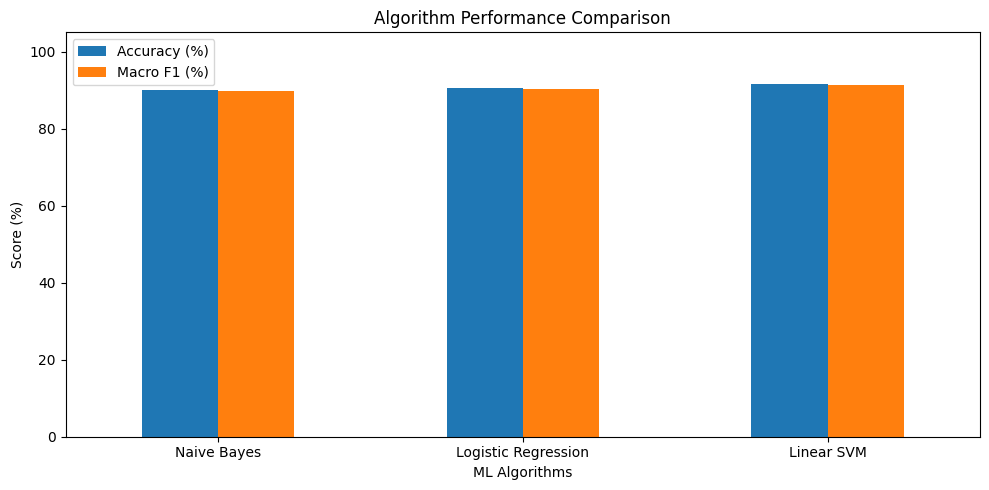

Selected Algorithm: Linear SVM

Final Test Results
Accuracy: 87.5 %
Macro F1: 87.26 %

Classification Report:
                        precision    recall  f1-score   support

            Encampment       0.75      1.00      0.86         6
     Illegal Fireworks       0.83      0.83      0.83         6
       Illegal Parking       1.00      1.00      1.00         6
     Missed Collection       1.00      0.50      0.67         6
    Noise - Commercial       1.00      1.00      1.00         6
      Street Condition       1.00      0.83      0.91         6
Street Light Condition       0.62      0.83      0.71         6
            WATER LEAK       1.00      1.00      1.00         6

              accuracy                           0.88        48
             macro avg       0.90      0.88      0.87        48
          weighted avg       0.90      0.88      0.87        48



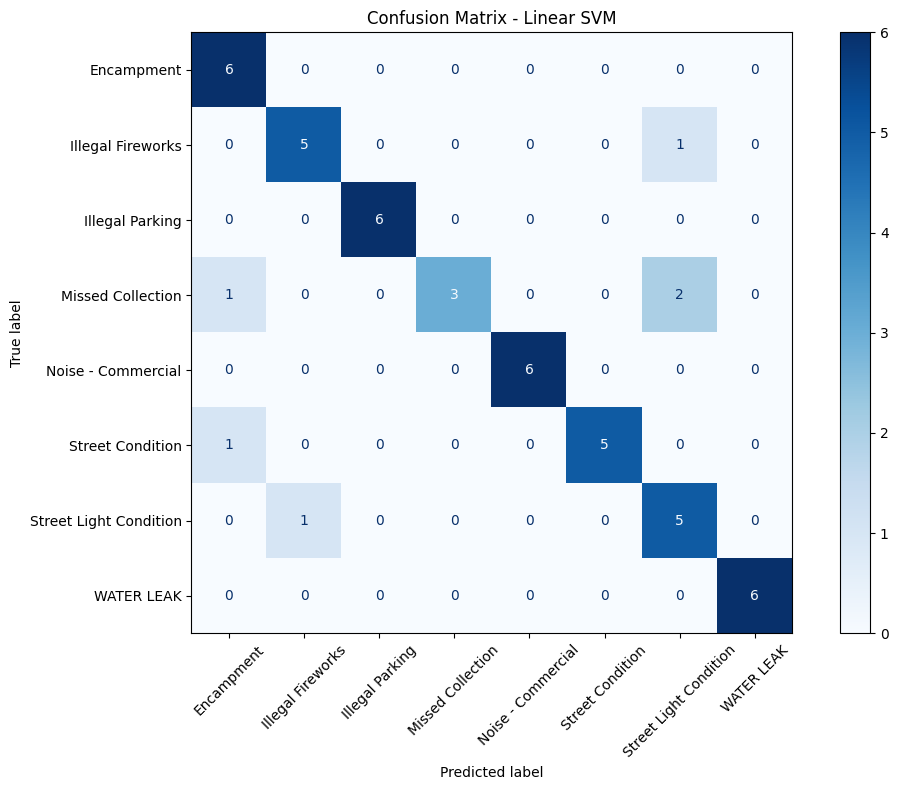

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Define algorithms
algorithms = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

# 2. Five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

cv_results = {}

for name, algorithm in algorithms.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            stop_words="english",
            sublinear_tf=True
        )),
        ("classifier", algorithm)
    ])

    scores = cross_validate(
        pipeline,
        X_train_citizen,
        y_train_citizen,
        cv=cv,
        scoring=scoring
    )

    cv_results[name] = scores

# 3. Display comparison
comparison = pd.DataFrame({
    name: {
        metric: scores[f"test_{metric}"].mean() * 100
        for metric in scoring
    }
    for name, scores in cv_results.items()
}).T

comparison.columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Macro F1 (%)"
]

print("5-Fold Cross-Validation Results:")
display(comparison.round(2))

# 4. Visualize algorithm comparison
comparison[["Accuracy (%)", "Macro F1 (%)"]].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 105)
)

plt.title("Algorithm Performance Comparison")
plt.ylabel("Score (%)")
plt.xlabel("ML Algorithms")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

# 5. Select best algorithm using CV Macro F1
best_name = max(
    cv_results,
    key=lambda name: cv_results[name]["test_f1_macro"].mean()
)

print("Selected Algorithm:", best_name)

# 6. Train selected pipeline on complete training data
best_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        stop_words="english",
        sublinear_tf=True
    )),
    ("classifier", algorithms[best_name])
])

best_pipeline.fit(X_train_citizen, y_train_citizen)

# 7. Final evaluation on untouched test data
final_predictions = best_pipeline.predict(X_test_citizen)

print("\nFinal Test Results")
print("Accuracy:", round(
    accuracy_score(y_test_citizen, final_predictions) * 100, 2
), "%")

print("Macro F1:", round(
    f1_score(y_test_citizen, final_predictions, average="macro") * 100, 2
), "%")

print("\nClassification Report:")
print(classification_report(
    y_test_citizen,
    final_predictions,
    zero_division=0
))

# 8. Confusion matrix visualization
fig, ax = plt.subplots(figsize=(11, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test_citizen,
    final_predictions,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()


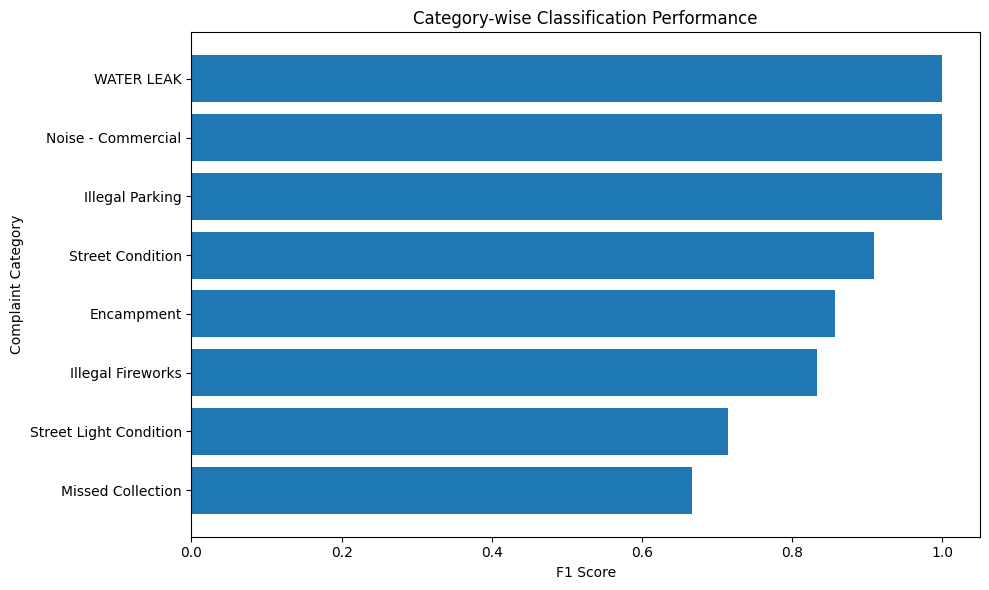

In [ ]:
from sklearn.metrics import f1_score
import pandas as pd
import matplotlib.pyplot as plt

category_f1 = f1_score(
    y_test_citizen,
    final_predictions,
    average=None,
    labels=best_pipeline.classes_
)

f1_df = pd.DataFrame({
    'Category': best_pipeline.classes_,
    'F1 Score': category_f1
}).sort_values('F1 Score')

plt.figure(figsize=(10, 6))

plt.barh(
    f1_df['Category'],
    f1_df['F1 Score']
)

plt.xlabel("F1 Score")
plt.ylabel("Complaint Category")
plt.title("Category-wise Classification Performance")
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()

In [ ]:
import joblib
import os

# Create model directory
os.makedirs("civicpulse_models", exist_ok=True)

# Save trained pipeline
joblib.dump(
    best_pipeline,
    "civicpulse_models/citizen_complaint_model.pkl"
)

print("Model saved successfully!")
print("Selected Algorithm:", best_name)

Model saved successfully!
Selected Algorithm: Linear SVM


In [ ]:
from google.colab import files

files.download(
    "civicpulse_models/citizen_complaint_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>